<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/03_ML_NLFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Non-linear Feature Transformation


---


A linear model calculates its output from a weighted combination of the input features (known as signal):

$$
\mathbf{w}^\intercal \mathbf{x} = \sum_{i=0}^{d} w_i x_i
$$

During training, the input values $\mathbf{x}$ are fixed and the learning algorithm adjusts the weights $\mathbf{w}$. For this reason, what matters to the learning algorithm is that the model remains linear with respect to its weights. The input features themselves, however, do not have to remain unchanged. We can first apply a non-linear transformation to the input and then use the transformed features with the same linear learning algorithms. We denote this transformation by: $$ \mathbf{z} = \Phi(\mathbf{x}) $$ where $\Phi$ maps the original input from the feature space $\mathcal{X}$ to a new feature space $\mathcal{Z}$. This idea can be used for both classification and regression, as we will see in the following examples.



# Classification


As not all data are linearly seperable, in fact the majority of real world problem are concerned with non-linearly seperable data. This trick is used to utilise linear models while still having non-linearly seperable data by transforming the features such that the newly transformed features are linearly seperable. This newly transformed data set—which is now linearly separable—is used as the new data set. For that purpose we can define the $\mathcal Z$-space which is the space that the transformed data belong to. Non-linear transformations can be used to transform data such that it becomes linearly separable given original data $\mathrm {x}_n \in \mathcal X$, we transform the data using $\mathrm {z}_i = \Phi (\mathrm {x}_i) \in \mathcal Z$, then separate data in the $\mathcal Z$ $\tilde {g} (\mathrm {z}) = \text {sign} (\tilde {w}^{\mathrm {T}} \mathrm {z})$, and finally classify in $\mathcal X$ such that $g(\mathrm {x}) = \tilde {g} (\Phi (\mathrm {x})) = \text {sign} (\tilde {w}^{\mathrm {T}} \Phi (\mathrm {x}))$. This process is summarised below:


$$
\begin{align}
\mathrm {x} = (x_0, x_1, \dots, x_d)\ &\xrightarrow{\Phi}\ \mathrm {z} = (z_0, z_1, \dots \dots, z_{\tilde d}) \\
\mathrm { x_1, x_2, \dots, x_n}\      &\xrightarrow{\Phi}\ \mathrm {z_1, z_2, \dots, z_n } \\
\mathrm { y_1, y_2, \dots, y_n}\      &\xrightarrow{\Phi}\ \mathrm {y_1, y_2, \dots, y_n } \\
\text {no weights in}\ \mathcal {X}\  &\phantom {\xrightarrow{\Phi}\ } \mathrm {\tilde {w}} = (w_0, w_1, \dots \dots, w_{\tilde {d}}) \\
g(\mathrm {x}) = \text {sign} (\mathrm {\tilde {w}^T z}) &= \text {sign} (\mathrm {\tilde {w}^T \Phi (x)})
\end{align}
$$


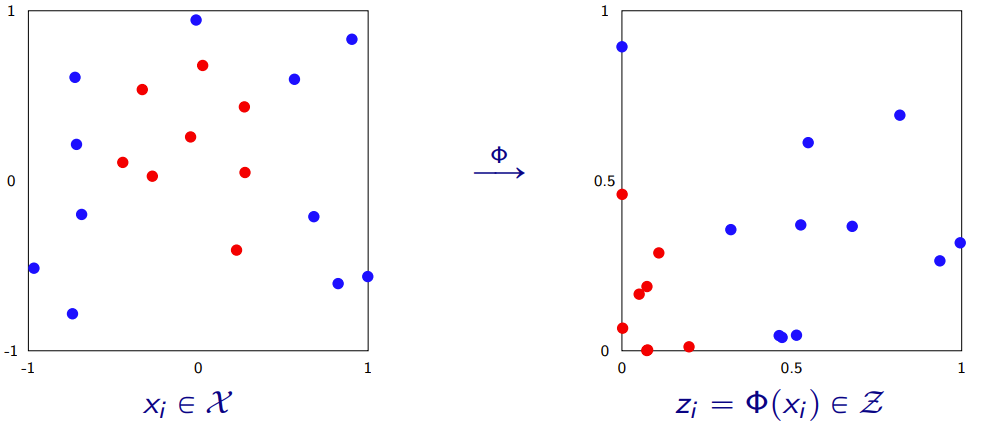

In the upcoming code cell, a piece of code is given that will generate a dummy non-linearly separable data for us. We will then use the Perceptron Learning Algorithm (PLA) that we learned about in the first exercise to classify this newly generated data. To make things more convenient for you, the code for the PLA is provided right below.

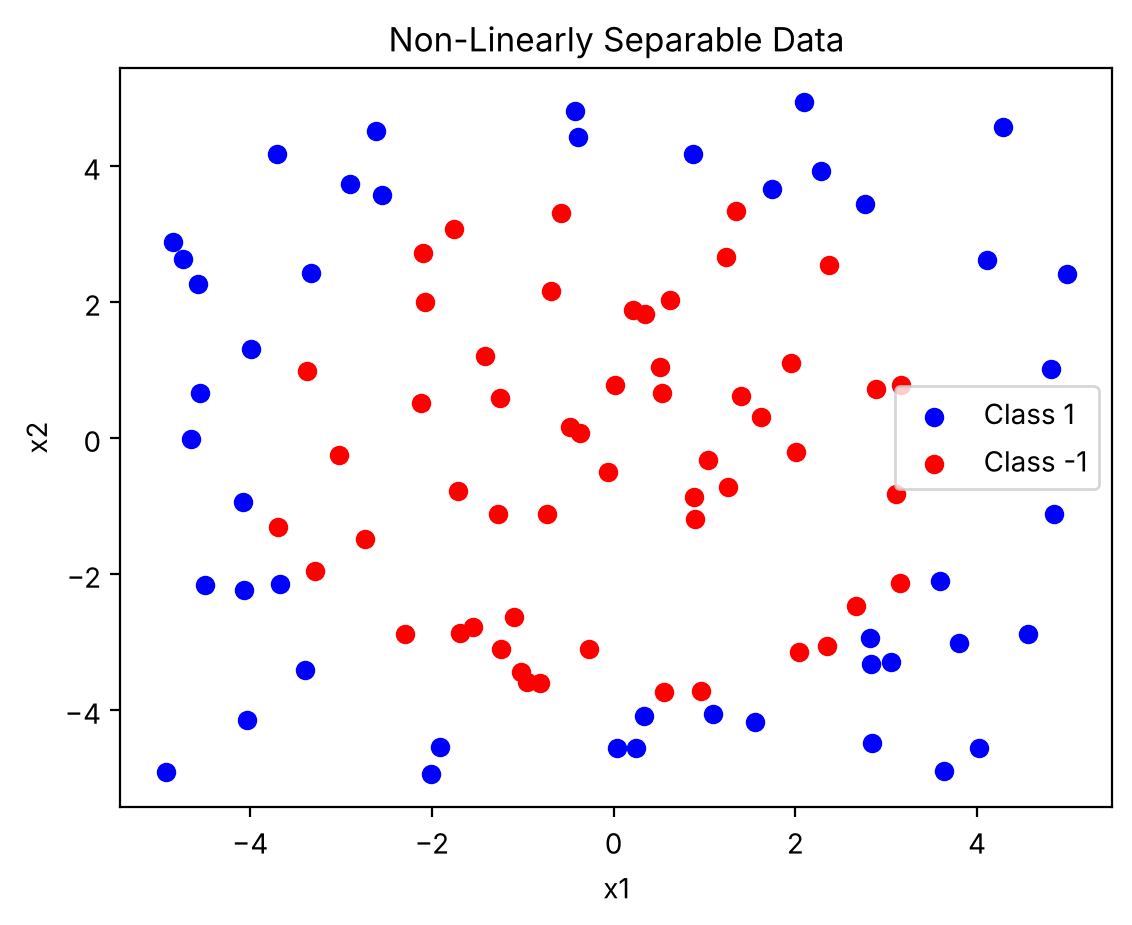

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def generate_non_linearly_separable_data(num_samples, random_seed=32):
    # Set the random seed for consistent data generation
    np.random.seed(random_seed)
    # Generate random data points for x1 and x2 in the range [-5, 5]
    x1 = np.random.uniform(-5, 5, num_samples)
    x2 = np.random.uniform(-5, 5, num_samples)

    # Assign labels such that the data points are not linearly separable
    labels = np.where(x1**2 + x2**2 >= 16, 1, -1)

    return x1, x2, labels

def plot_data(x1, x2, labels, title):
    # Plot the data points with different colors for each class
    plt.scatter(x1[labels==1], x2[labels==1], c='b', marker='o', label='Class 1')
    plt.scatter(x1[labels==-1], x2[labels==-1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title(title)
    plt.show()

num_samples_per_class = 50  # Half of the samples for each class
x1, x2, labels = generate_non_linearly_separable_data(num_samples_per_class * 2)

# Stack the data in one numpy array to distinguish them from the tranformed data later on

X_original = np.column_stack((x1, x2))

# Plot non-linearly separable data
plot_data(x1, x2, labels, 'Non-Linearly Separable Data')

In [2]:
# PLA code below

def predict(W, X):
        """ Return class label after each setp """
        return np.where(net_input(W, X) >= 0.0, 1, -1)

def net_input(W, X):
        """ Calculate net input """
        return np.dot(X, W[1:]) + W[0]

def plot_boundary(W, X, y):
    """Function to plot the boundary defined by the weights. Given equation."""
    """w0 + w1*x1 + w2*x2 = 0, used to generate the line."""

    # Calculate the slope and y-intercept of the boundary line
    slope = -W[1] / W[2]
    intercept = -W[0] / W[2]

    # Get the minimum and maximum x values from the dataset
    x_min = np.min(X[:, 0])
    x_max = np.max(X[:, 0])

    # Generate points for the boundary line to cover the whole plot
    x_vals = np.array([x_min, x_max])
    y_vals = slope * x_vals + intercept

    # This part here define the x-axis and y-axis style according to the data we are using
    plt.scatter(X[y==1, 0], X[y==1, 1], c='b', marker='o', label='Class 1')
    plt.scatter(X[y==-1, 0], X[y==-1, 1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title('title')

    # Plot the line using the calculated points
    plt.plot(x_vals, y_vals, 'black')

    plt.show()

def plot_errors(error):
    plt.plot(range(1, len(error) + 1), error,marker='o')
    plt.xlabel('Iterations')
    plt.ylabel('Number of misclassifications')
    # Set the x-axis ticks to display only integer values
    # Set the x-axis ticks to be automatically determined based on available space
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

def pla(n_iter, X, y):
        W = np.zeros(1 + X.shape[1])
        errors_ = []
        for i in range(n_iter):
            for j, (xi, target) in enumerate(zip(X,y)):
         #     update = target - predict(W, xi)
         #     W += 0.5*update*np.append(1,xi)
              if predict(W, xi) != target:
                  W = W + target * np.append(1,xi)
            # errors on whole dataset
            errors = 0
            for j, (xi, target) in enumerate(zip(X, y)):
                if predict(W, xi) != target:
                    errors += 1
            # -------------------------------------------
            errors_.append(errors)
            i += 1
            print ("Iteration: ", i)
            print("Weights: ", W)
            print("Misclassified Samples: ", errors)
            plot_boundary(W,X,y)  #When weights are updated we plot the boundary

        plot_errors(errors_)

## Task 1 [40 marks]

1. Write a function to transform the provided data while retaining its original feature space dimensions. The objective is to get linearly separable data through this transformation. The resulting transformed data, represented as `x1_transformed` and `x2_transformed` can then be merged into a single NumPy array, serving as input for the pla function as we did with the original data.

2. Generate a plot that visually demonstrates the linear separability achieved by the transformed data. Execute the Perceptron Learning Algorithm (`pla`) using this transformed data. Present the following outcomes:
  - Final classifier weights.
  - Visualisation of the decision boundary.
  - Display of correctly classified samples.
  - Identification of the iteration at which the PLA achieved perfect classification.

3. Create a plot of the original labeled data and overlay the deicision boundary expressed in the original coordinates.

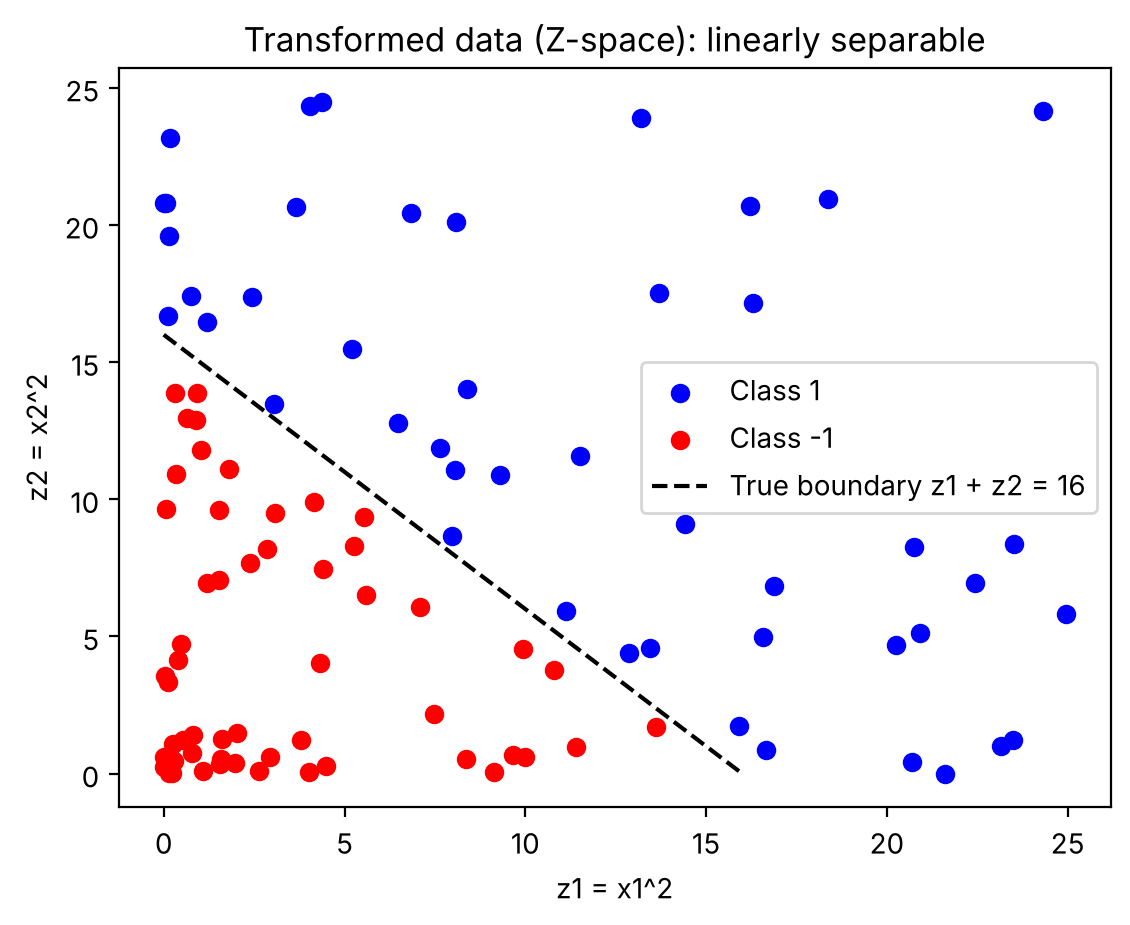

In [3]:
# Task 1
# The labels are defined by a circle:  y = +1 if x1^2 + x2^2 >= 16, else -1.
# Squaring each feature keeps the number of dimensions at 2 but turns the circle
# into a straight line in Z-space:  z1 + z2 = 16  (z1 = x1^2, z2 = x2^2).

def transform(x1, x2):
    """Non-linear transform Phi(x) = (x1^2, x2^2) - same 2D feature space size."""
    x1_transformed = x1 ** 2
    x2_transformed = x2 ** 2
    return x1_transformed, x2_transformed

x1_transformed, x2_transformed = transform(x1, x2)
X_transformed = np.column_stack((x1_transformed, x2_transformed))

# Plot showing that the transformed data are linearly separable
plt.scatter(x1_transformed[labels == 1], x2_transformed[labels == 1], c='b', marker='o', label='Class 1')
plt.scatter(x1_transformed[labels == -1], x2_transformed[labels == -1], c='r', marker='o', label='Class -1')
zz = np.linspace(0, 16, 50)
plt.plot(zz, 16 - zz, 'k--', label='True boundary z1 + z2 = 16')
plt.xlabel('z1 = x1^2')
plt.ylabel('z2 = x2^2')
plt.title('Transformed data (Z-space): linearly separable')
plt.legend()
plt.show()

The PLA function from the tutorial is reused with three small changes:
* It stops as soon as there are **0 misclassifications**. That gives the iteration where perfect classification happened, and avoids drawing a plot for every iteration.
* It **returns** the weights and the error history.
* The boundary plot gets proper axis labels and a title, since the tutorial one is literally titled `'title'`.

The update rule is unchanged: `W ← W + y_i·[1, z_i]`.

Iteration:   1 | Weights: [-17.      9.685   8.436] | Misclassified: 45
Iteration:   2 | Weights: [-31.      1.753  16.105] | Misclassified: 30
Iteration:   3 | Weights: [-42.      2.753  19.9  ] | Misclassified: 30
Iteration:   4 | Weights: [-53.      4.57   11.744] | Misclassified: 27
Iteration:   5 | Weights: [-64.      9.664  20.147] | Misclassified: 34
Iteration:   6 | Weights: [-75.     -0.726  11.582] | Misclassified: 33
Iteration:   7 | Weights: [-83.     12.913  14.071] | Misclassified: 30
Iteration:   8 | Weights: [-93.      6.492  18.989] | Misclassified: 24
Iteration:   9 | Weights: [-102.       2.908   12.677] | Misclassified: 24
Iteration:  10 | Weights: [-106.       1.829   11.724] | Misclassified: 25
Iteration:  11 | Weights: [-111.       3.241    9.183] | Misclassified: 17
Iteration:  12 | Weights: [-114.       1.936   11.72 ] | Misclassified: 24
Iteration:  13 | Weights: [-123.       3.128   10.202] | Misclassified: 19
Iteration:  14 | Weights: [-129.      16.286   20

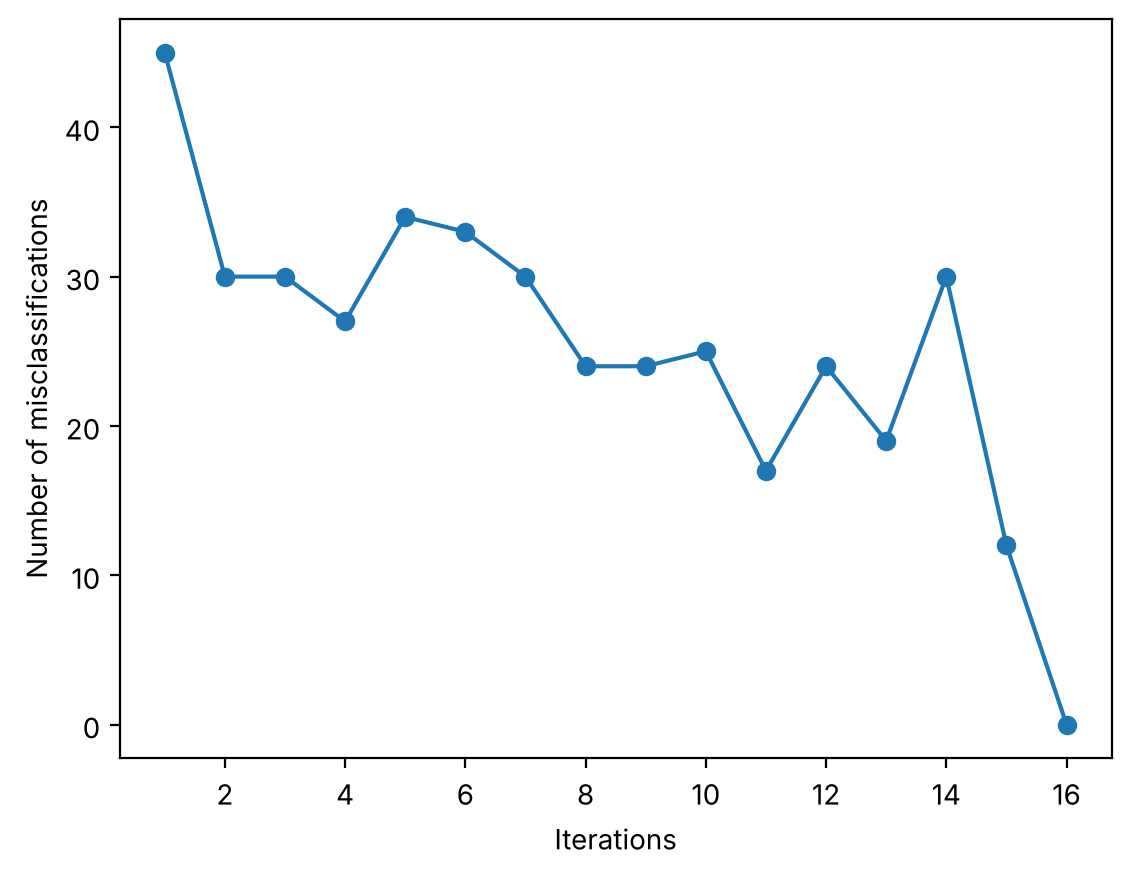

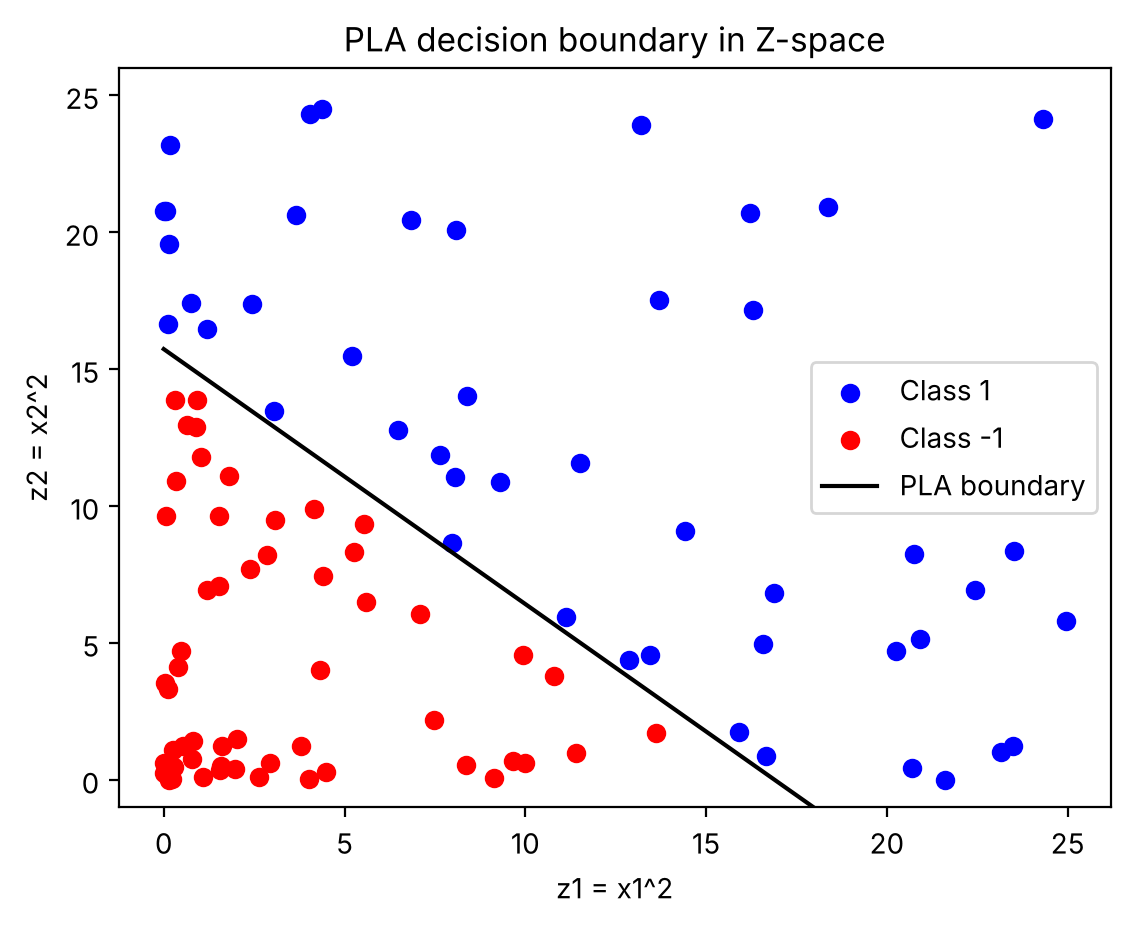

Correctly classified: 100 / 100  (100 %)


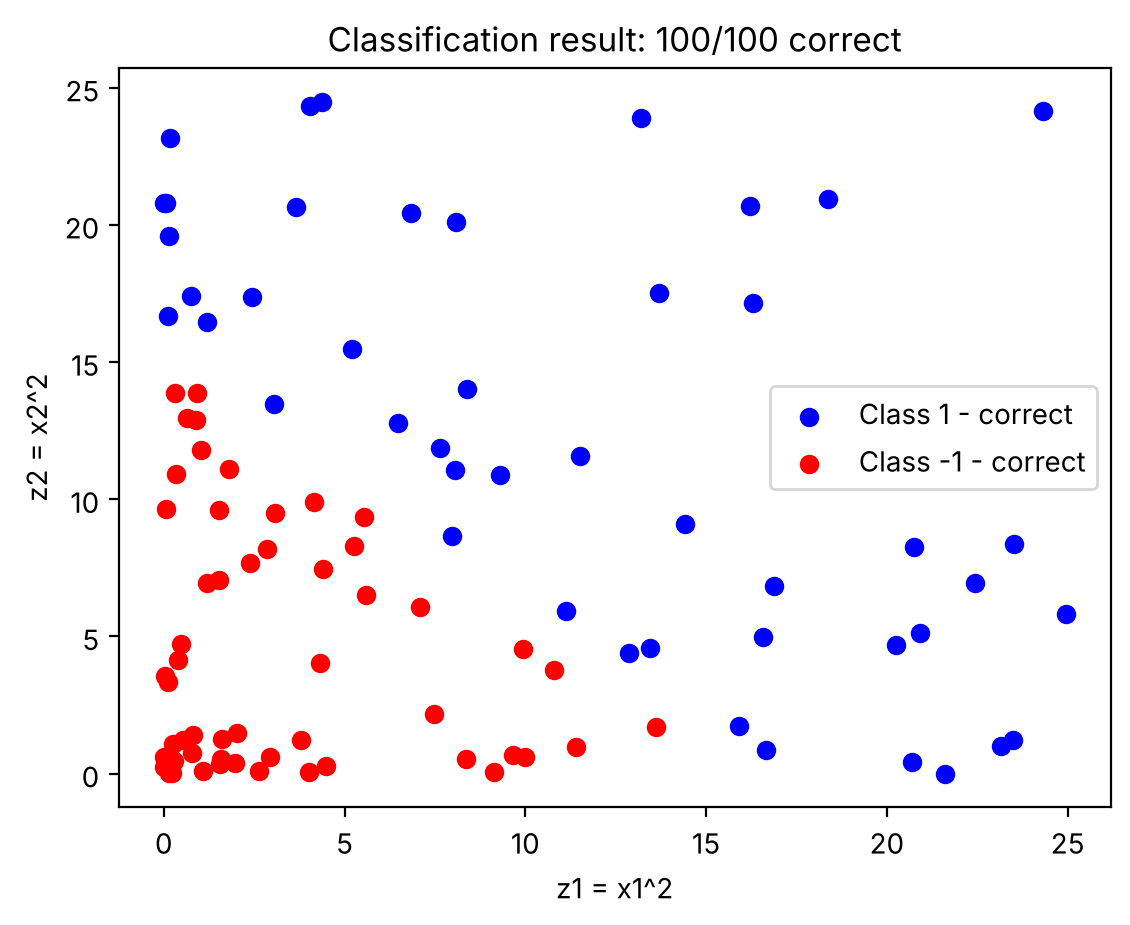

Boundary in X-space: 8.108*x1^2 + 8.707*x2^2 = 137.000  ->  ellipse with semi-axes a = 4.111, b = 3.967 (true circle radius = 4)


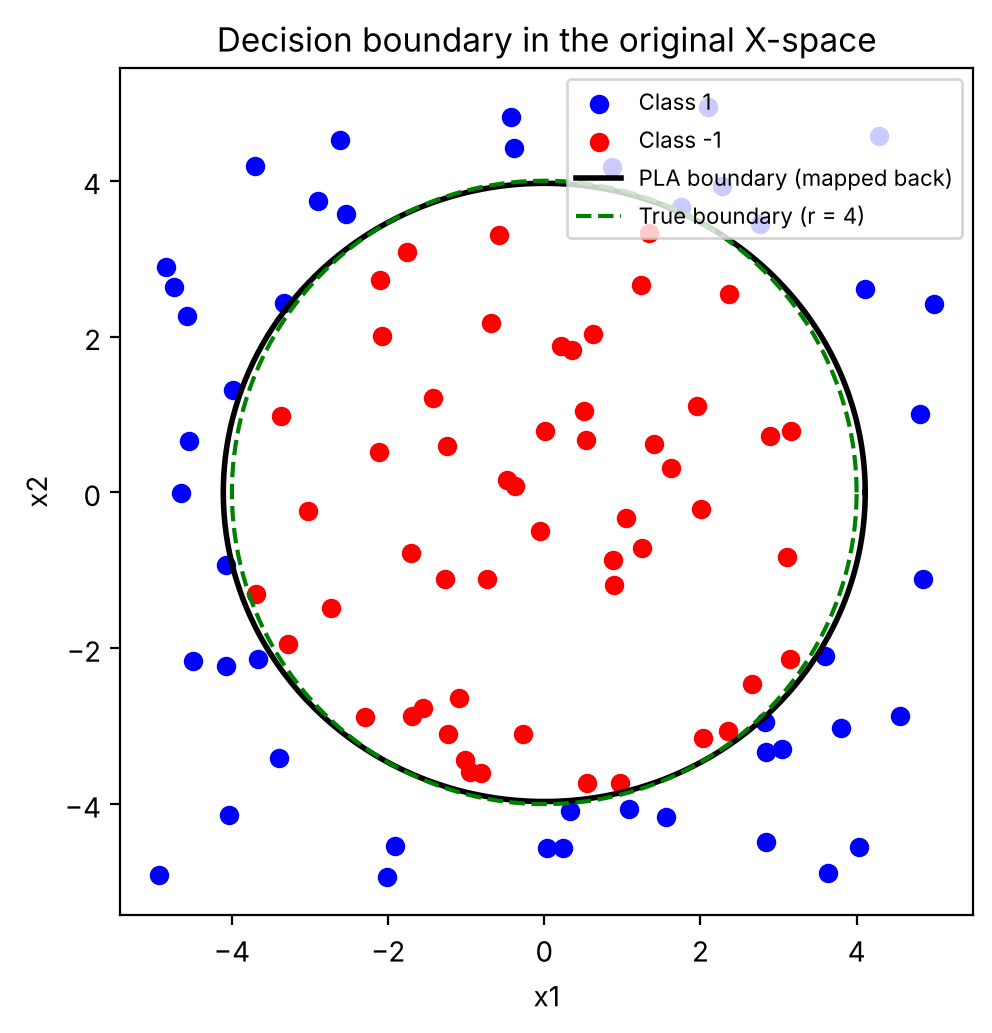

In [4]:
# Task 1 (continued)

def pla_t1(n_iter, X, y):
    W = np.zeros(1 + X.shape[1])
    errors_ = []
    for i in range(n_iter):
        for xi, target in zip(X, y):
            if predict(W, xi) != target:
                W = W + target * np.append(1, xi)
        errors = int(np.sum(predict(W, X) != y))
        errors_.append(errors)
        print(f"Iteration: {i + 1:3d} | Weights: {np.round(W, 3)} | Misclassified: {errors}")
        if errors == 0:
            break
    return W, errors_

W_t1, errors_t1 = pla_t1(100, X_transformed, labels)
perfect_iter = len(errors_t1) if errors_t1[-1] == 0 else None

# --- Final weights ---
print("\nFinal weights W = [w0, w1, w2] =", W_t1)
print("PLA achieved perfect classification at iteration:", perfect_iter)

# --- Misclassifications per iteration ---
plot_errors(errors_t1)

# --- Decision boundary in Z-space ---
z_vals = np.array([0, X_transformed[:, 0].max()])
plt.scatter(x1_transformed[labels == 1], x2_transformed[labels == 1], c='b', marker='o', label='Class 1')
plt.scatter(x1_transformed[labels == -1], x2_transformed[labels == -1], c='r', marker='o', label='Class -1')
plt.plot(z_vals, -(W_t1[0] + W_t1[1] * z_vals) / W_t1[2], 'k', label='PLA boundary')
plt.ylim(-1, 26)
plt.xlabel('z1 = x1^2'); plt.ylabel('z2 = x2^2')
plt.title('PLA decision boundary in Z-space')
plt.legend(); plt.show()

# --- Correctly classified samples ---
pred_t1 = predict(W_t1, X_transformed)
correct = pred_t1 == labels
print(f"Correctly classified: {correct.sum()} / {len(labels)}  ({100 * correct.mean():.0f} %)")
plt.scatter(x1_transformed[correct & (labels == 1)], x2_transformed[correct & (labels == 1)],
            c='b', marker='o', label='Class 1 - correct')
plt.scatter(x1_transformed[correct & (labels == -1)], x2_transformed[correct & (labels == -1)],
            c='r', marker='o', label='Class -1 - correct')
if (~correct).any():
    plt.scatter(x1_transformed[~correct], x2_transformed[~correct], c='k', marker='x', s=80, label='Misclassified')
plt.xlabel('z1 = x1^2'); plt.ylabel('z2 = x2^2')
plt.title(f'Classification result: {correct.sum()}/{len(labels)} correct')
plt.legend(); plt.show()

# --- Part 3: decision boundary back in the ORIGINAL X-space ---
# w0 + w1*x1^2 + w2*x2^2 = 0  ->  ellipse  x1^2/a^2 + x2^2/b^2 = 1
a = np.sqrt(-W_t1[0] / W_t1[1])
b = np.sqrt(-W_t1[0] / W_t1[2])
t = np.linspace(0, 2 * np.pi, 400)
print(f"Boundary in X-space: {W_t1[1]:.3f}*x1^2 + {W_t1[2]:.3f}*x2^2 = {-W_t1[0]:.3f}"
      f"  ->  ellipse with semi-axes a = {a:.3f}, b = {b:.3f} (true circle radius = 4)")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(x1[labels == 1], x2[labels == 1], c='b', marker='o', label='Class 1')
plt.scatter(x1[labels == -1], x2[labels == -1], c='r', marker='o', label='Class -1')
plt.plot(a * np.cos(t), b * np.sin(t), 'k', linewidth=2, label='PLA boundary (mapped back)')
plt.plot(4 * np.cos(t), 4 * np.sin(t), 'g--', label='True boundary (r = 4)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Decision boundary in the original X-space')
plt.axis('equal'); plt.legend(loc='upper right', fontsize=8); plt.show()

**Task 1 notes.** The transform $\Phi(x_1, x_2) = (x_1^2, x_2^2)$ keeps two features and turns the circular class boundary $x_1^2 + x_2^2 = 16$ into the straight line $z_1 + z_2 = 16$, so PLA can separate the data perfectly. The learned line $w_0 + w_1 z_1 + w_2 z_2 = 0$ maps back to $w_1 x_1^2 + w_2 x_2^2 = -w_0$, which is an **ellipse** in the original space. It is close to the true circle of radius 4 but not exactly the same, because PLA stops at the first line that separates the training points, not the best one.

# Regression



The same idea can also be applied to regression. A standard linear regression model represents the target as a linear combination of its input features. This works well when a straight line, plane, or hyperplane gives a reasonable description of the relationship between the inputs and the target. Some datasets, however, follow curved or more complicated patterns. Instead of changing the regression algorithm itself, we can transform the original features and fit a linear model using the transformed ones. A common example is a **polynomial transformation**. For a single feature $x_1$, a quadratic transformation can create the features: $$ 1,\ x_1,\ x_1^2 $$ The model can then take the form: $$ \hat{y} = w_0 + w_1x_1 + w_2x_1^2 $$ Although this produces a curved relationship with respect to $x_1$, the model is still linear in the weights $w_0$, $w_1$, and $w_2$. For two input features, $\mathbf{x} = (1, x_1, x_2)$, a degree-2 polynomial transformation can be written as: $$ \mathbf{x} = (1, x_1, x_2) \;\xrightarrow{\Phi}\; \mathbf{z} = (1, x_1, x_2, x_1x_2, x_1^2, x_2^2) $$ The transformed features can then be passed to a linear regression model in exactly the same way as the original features. Increasing the polynomial degree gives the model more flexibility to follow non-linear patterns in the data. The figure below shows this effect for a single input feature. The top-left plot corresponds to a standard linear fit of degree 1, while the remaining plots use higher-degree polynomial features.



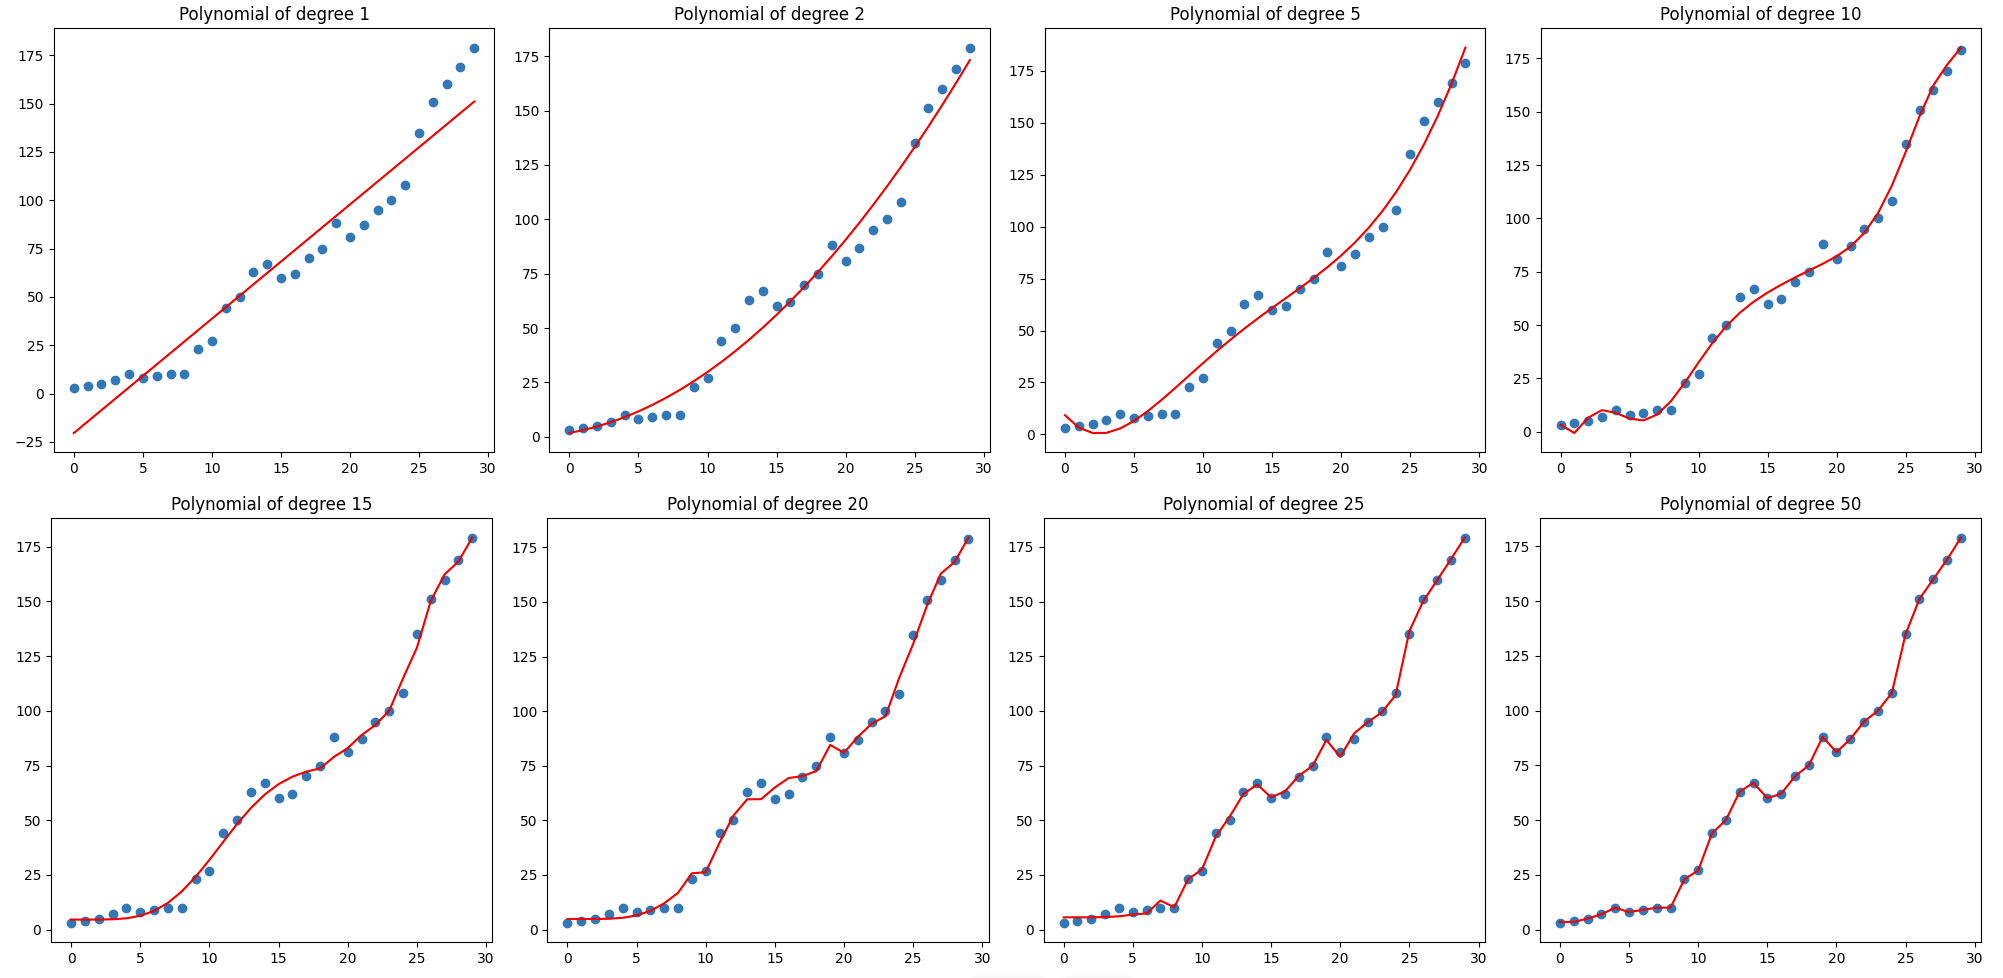

In the upcoming code cell, a piece of code is given that will generate a dummy data for regression.


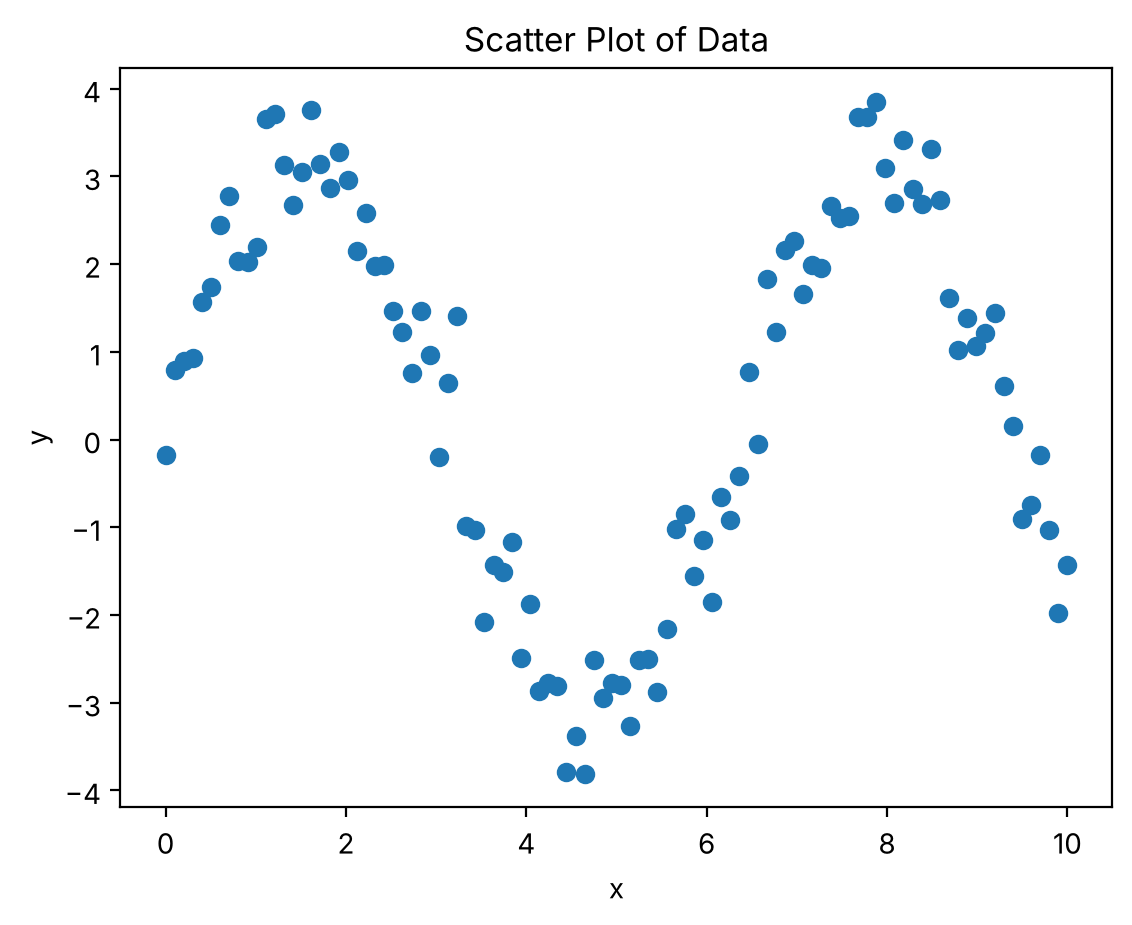

In [5]:
np.random.seed(32)  # Set a seed for reproducibility

# Generate data points with a sine-like pattern and noise
x = np.linspace(0, 10, 100)
y = 3 * np.sin(x) + np.random.normal(0, 0.5, 100)

# Plot the data
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter Plot of Data')
plt.show()

## Task 2 [60 marks]

You are required to create a function(s) that takes a single-variable input `x` and generates a polynomial transformation of a specified degree `d`. The function should provide the option to include a bias term or not, controlled by the logical parameter `include_bias`. You will then use the tranformed data to train linear regression model and get the MSE for each case.

**1. Function Description:**

- Accepts the input variable `x`.
- Accepts the polynomial degree `d`.
- Accepts the logical parameter `include_bias` (either `True` or `False`).
- Generates a polynomial transformation of degree `d` based on the value of `include_bias`. If `include_bias` is `True`, the transformation includes the bias term `1` as the first component. Otherwise, the transformation starts directly from `x^1`.
- Returns the polynomial transformation as a vector `z`.
-For instance, if you choose `d=5` and `include_bias=True`, the generated output will be `z = [1, x, x^2, x^3, x^4, x^5]`. On the other hand, if `include_bias=False`, the generated output will be `z = [x, x^2, x^3, x^4, x^5]`.

**3. Training Linear Regression Model:**
  - Use the provided degrees `[1, 3, 5, 7, 9, 11, 13, 15]`.
  - For each degree in the list, apply the polynomial transformation to the input data `x`.
  - Train a linear regression model using the transformed data and the original `y` data.
  - Visualise the results in a fixed **2×4 subplot layout**, where each subplot corresponds to one of the eight polynomial degrees. In each subplot, plot both the original data points and the predicted values from the linear regression model. (You can use the figure with the eight plots in the description as a reference of how your visulisation should be.)
  - Additionally, For each polynomial degree, calculate two MSEs: one against the noisy data samples $y$ and one against the true curve $3\cdot \sin(x)$ (`3*np.sin(x)`). Display both values above each plot, clearly labeled. Note: you can also include the true curve in each plot as dashed line. (Use proper legends to be clear)



> In this task you are allowed to use scikit-learn library to fit the linear regression model and for calculating the MSE. However, you are expected to create your own user-defined function for generating the polynomial data as usual. Below are the corresponding commands that you can import:
- `from sklearn.linear_model import LinearRegression`
- `from sklearn.metrics import mean_squared_error`



In [6]:
# Task 2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def polynomial_transform(x, d, include_bias=True):
    """
    Polynomial transformation of a single variable x up to degree d.
    include_bias=True  -> z = [1, x, x^2, ..., x^d]
    include_bias=False -> z = [x, x^2, ..., x^d]
    Returns an (n_samples, n_terms) array (one row z per sample).
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    start = 0 if include_bias else 1
    return np.column_stack([x ** k for k in range(start, d + 1)])

# Quick check of the function on a single value
print("d=5, include_bias=True :", polynomial_transform([2.0], 5, True))
print("d=5, include_bias=False:", polynomial_transform([2.0], 5, False))

d=5, include_bias=True : [[ 1.  2.  4.  8. 16. 32.]]
d=5, include_bias=False: [[ 2.  4.  8. 16. 32.]]


**Scaling note.** `x` runs from 0 to 10, so $x^{15} \approx 10^{15}$. Columns that different in size make the least-squares problem badly conditioned. I tried it with raw `x`, and the degree-13 and degree-15 models then came out *worse* than degree 5 even on the training data, which is a numerical artefact. To avoid this, `x` is divided by its maximum (scaled to [0, 1]) before the transform. A polynomial in $x/10$ is still a polynomial of the same degree in $x$, so the model family is unchanged and only the numerics improve.

The bias is included through the transform (`include_bias=True`), so `LinearRegression` is created with `fit_intercept=False` to avoid adding a second intercept.

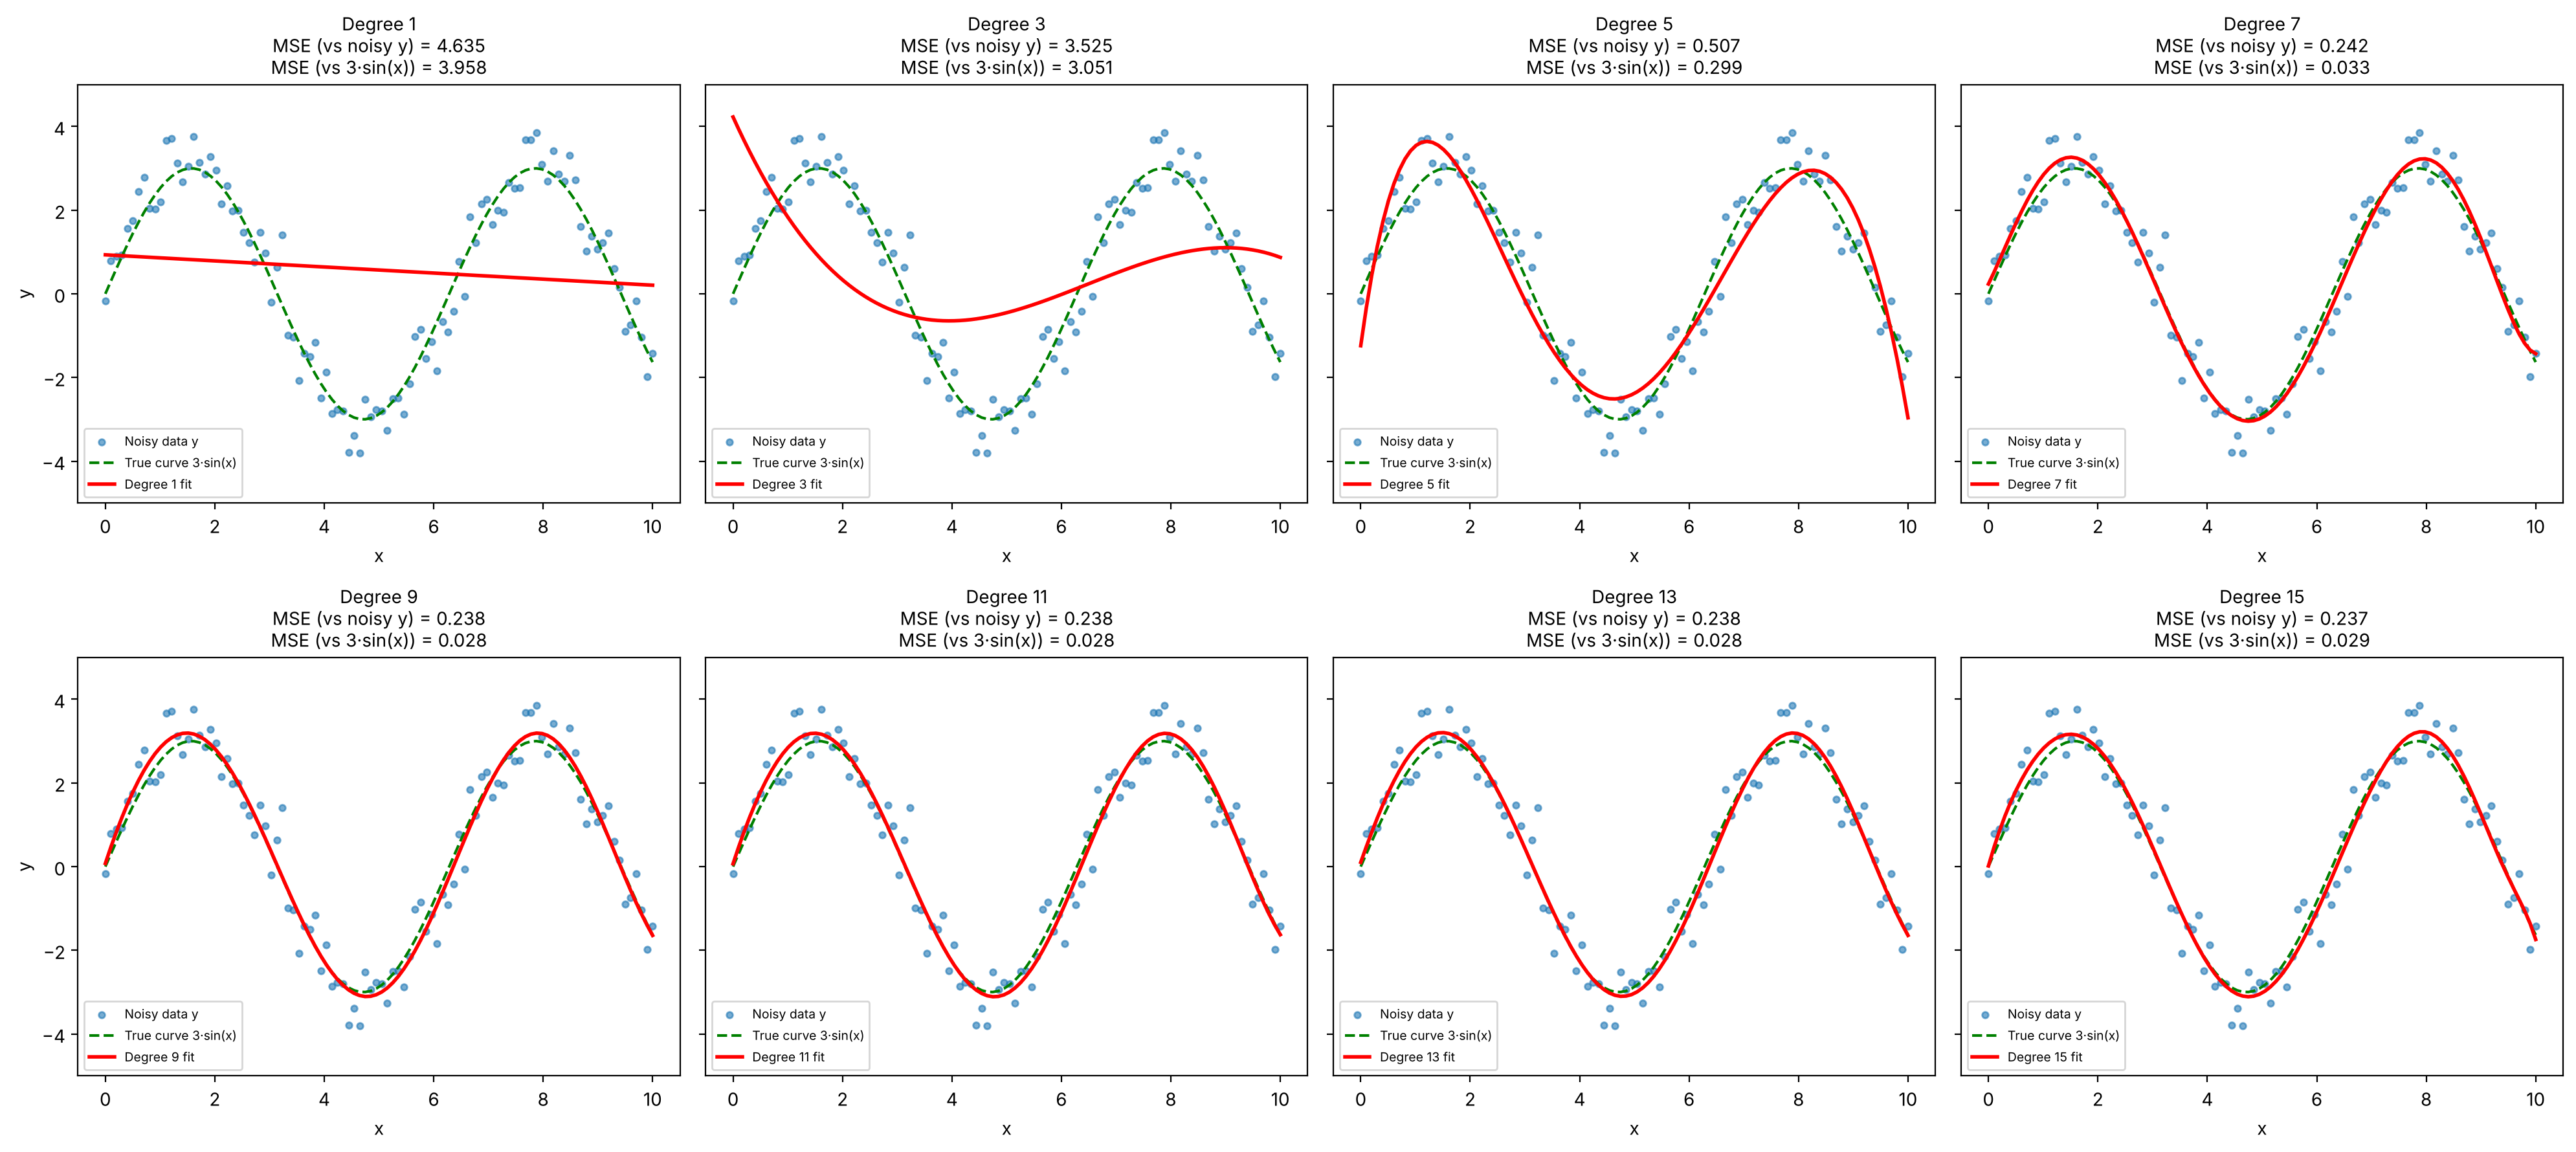

Degree |  MSE vs noisy y |  MSE vs 3sin(x)
     1 |          4.6355 |          3.9584
     3 |          3.5246 |          3.0508
     5 |          0.5068 |          0.2991
     7 |          0.2419 |          0.0331
     9 |          0.2376 |          0.0281
    11 |          0.2376 |          0.0279
    13 |          0.2378 |          0.0282
    15 |          0.2366 |          0.0290

Lowest MSE against the true curve: degree 11 (0.0279)


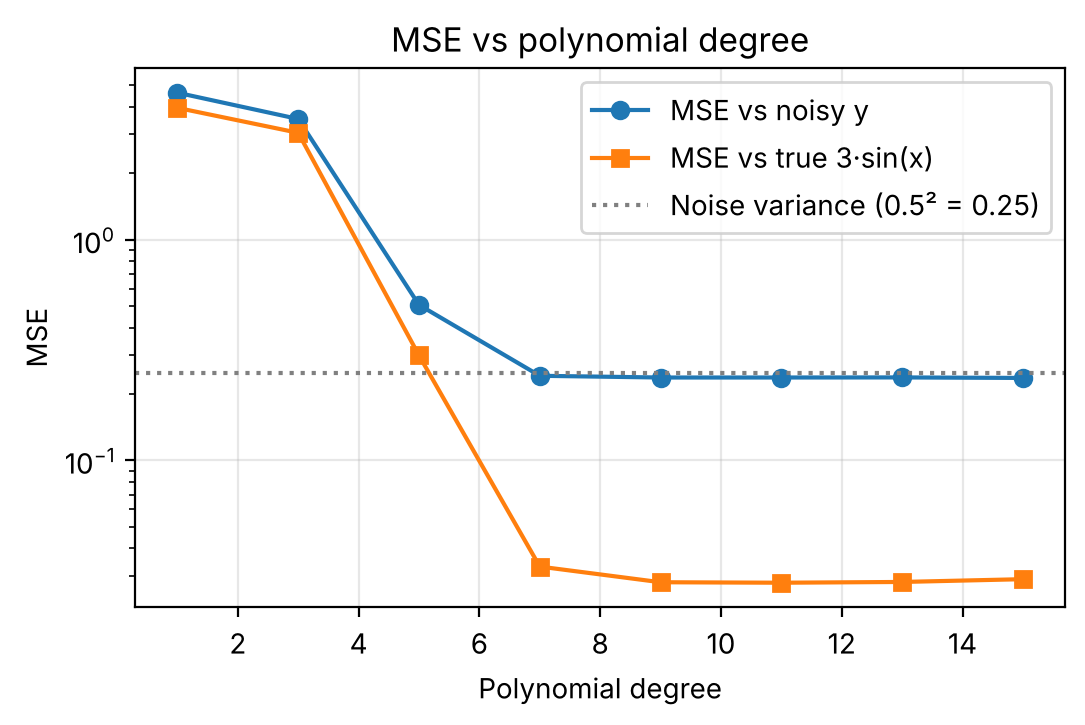

In [7]:
# Task 2 (continued)
degrees = [1, 3, 5, 7, 9, 11, 13, 15]
x_scaled = x / x.max()          # scale to [0, 1] for numerical stability
y_true = 3 * np.sin(x)

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
summary = []
for ax, d in zip(axes.flatten(), degrees):
    Z = polynomial_transform(x_scaled, d, include_bias=True)
    model = LinearRegression(fit_intercept=False).fit(Z, y)
    y_pred = model.predict(Z)

    mse_noisy = mean_squared_error(y, y_pred)
    mse_true = mean_squared_error(y_true, y_pred)
    summary.append((d, mse_noisy, mse_true))

    ax.scatter(x, y, s=12, color='tab:blue', alpha=0.6, label='Noisy data y')
    ax.plot(x, y_true, 'g--', linewidth=1.5, label='True curve 3·sin(x)')
    ax.plot(x, y_pred, 'r', linewidth=2, label=f'Degree {d} fit')
    ax.set_title(f"Degree {d}\nMSE (vs noisy y) = {mse_noisy:.3f}\nMSE (vs 3·sin(x)) = {mse_true:.3f}", fontsize=10)
    ax.set_xlabel('x')
    ax.set_ylim(-5, 5)
    ax.legend(fontsize=7, loc='lower left')
axes[0, 0].set_ylabel('y'); axes[1, 0].set_ylabel('y')
plt.tight_layout()
plt.show()

print(f"{'Degree':>6} | {'MSE vs noisy y':>15} | {'MSE vs 3sin(x)':>15}")
for d, a, b in summary:
    print(f"{d:>6} | {a:>15.4f} | {b:>15.4f}")

best = min(summary, key=lambda s: s[2])
print(f"\nLowest MSE against the true curve: degree {best[0]} ({best[2]:.4f})")

plt.figure(figsize=(6, 3.5))
plt.plot(degrees, [s[1] for s in summary], 'o-', label='MSE vs noisy y')
plt.plot(degrees, [s[2] for s in summary], 's-', label='MSE vs true 3·sin(x)')
plt.axhline(0.25, color='grey', linestyle=':', label='Noise variance (0.5² = 0.25)')
plt.xlabel('Polynomial degree'); plt.ylabel('MSE'); plt.yscale('log')
plt.title('MSE vs polynomial degree'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Task 2 notes.**
* **Degrees 1 and 3 underfit.** A line or a cubic cannot follow the oscillations of $3\sin(x)$ over [0, 10], so both MSEs are high.
* **From degree 7 upwards the fit follows the sine closely.** The MSE against the noisy samples levels off at about 0.24, which is just under the noise variance of 0.25. That is the best you can expect, because the remaining error is the random noise itself.
* **The MSE against the true curve is the real test of generalisation.** It is lowest around degree 9–11 and then creeps up again at degree 15. The training MSE keeps falling slightly, so the extra flexibility is starting to fit the noise rather than the underlying function. That is the start of **overfitting**.
* The degree-13 training MSE is a tiny bit higher than degree 11 (difference about 0.0002). This is numerical precision in the high powers of $x$, not a real effect.